# 🛍️📈 ML Portfolio Project — Classification & Regression

**Project A (Classification):** Predict whether an e-commerce order will be **returned** (`return_risk_label`)  
**Project B (Regression):** Predict **14-day revenue** of an influencer campaign (`campaign_revenue_usd`)

---
### How to run this notebook in Google Colab
1. Upload the two CSV files when asked in **Section 0** (or place them in the Colab file panel, `/content`):
   - `ecommerce_return_classification.csv`
   - `influencer_campaign_regression.csv`
2. Run all cells top-to-bottom (**Runtime → Run all**). Grid searches take a few minutes in total.
3. The deployment section (Gradio + Streamlit) creates a `deploy/` folder you can download.

### Contents (mapped to the grading rubric)
| Part | Sections |
|---|---|
| **0** | Setup & data loading |
| **A – Classification** | A1 Problem definition · A2 EDA · A3 Preprocessing & feature selection · A4 Models + cross-validation · A5 GridSearchCV · A6 Evaluation · A7 Comparison & final model · A8 Business interpretation |
| **B – Regression** | B1 – B8 (same structure) |
| **C – Deployment** | Save models · Gradio app · Streamlit app |
| **D – Wrap-up** | Summary & limitations |

## 0. Setup & Data Loading

In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import joblib
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold,
                                     cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              RandomForestRegressor, GradientBoostingRegressor)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RS = 42                      # random seed for reproducibility
np.random.seed(RS)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("Setup complete.")

Setup complete.


In [2]:
CLF_FILE = "ecommerce_return_classification.csv"
REG_FILE = "influencer_campaign_regression.csv"

def find_file(name):
    for d in [".", "/content", "/content/drive/MyDrive", "/mnt/project"]:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    return None

missing = [f for f in (CLF_FILE, REG_FILE) if find_file(f) is None]
if missing:
    try:
        from google.colab import files          # only exists inside Colab
        print("Please upload:", missing)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Place these files next to the notebook: {missing}")

CLF_PATH, REG_PATH = find_file(CLF_FILE), find_file(REG_FILE)
print("Classification data:", CLF_PATH)
print("Regression data    :", REG_PATH)

Classification data: ./ecommerce_return_classification.csv
Regression data    : ./influencer_campaign_regression.csv


### Helper functions used by both projects
Small reusable utilities (IQR outlier table, preprocessing builder, deployment metadata) so the main workflow stays readable.

In [3]:
def iqr_outlier_table(df, cols):
    """Count outliers per column using the 1.5 x IQR rule."""
    rows = []
    for c in cols:
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
        rows.append({"feature": c, "lower_bound": lo, "upper_bound": hi,
                     "n_outliers": n_out, "pct_outliers": 100 * n_out / len(df)})
    return pd.DataFrame(rows).set_index("feature")


def build_preprocessor(num_cols, bin_cols, cat_cols):
    """Scale numeric, pass binary flags through, one-hot encode categoricals."""
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("bin", "passthrough", bin_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])


def build_meta(X_ref, num_cols, bin_cols, cat_cols, extra=None):
    """Describe the model's input form (used to auto-build the Gradio/Streamlit UIs)."""
    feats = []
    for c in num_cols:
        s = X_ref[c]
        feats.append({"name": c, "type": "number",
                      "min": float(s.min()), "max": float(s.max()),
                      "default": float(s.median()),
                      "int": bool(pd.api.types.is_integer_dtype(s))})
    for c in bin_cols:
        feats.append({"name": c, "type": "binary", "choices": [0, 1], "default": 0})
    for c in cat_cols:
        vals = sorted(X_ref[c].unique().tolist())
        feats.append({"name": c, "type": "category", "choices": vals,
                      "default": X_ref[c].mode()[0]})
    return {"features": feats, "extra": extra or {}}

---
# PART A — CLASSIFICATION: E-commerce Return Risk
---
## A1. Problem Definition

**Business problem.** Online fashion retailers lose a large share of revenue to returns (reverse logistics, re-stocking, markdown of returned goods). If the retailer can predict *at checkout* that an order is likely to be returned, it can intervene early — e.g. show fit guidance, nudge the shopper to choose one size instead of several, or flag the order for review.

| Item | Description |
|---|---|
| **Target** | `return_risk_label` — 1 = order returned, 0 = order kept |
| **Features** | Cart value, customer's past return rate, size-bracketing flag, delivery days, discount %, product category, fit-review sentiment, newsletter status, browser, device, packaging colour, loyalty card colour |
| **ML task** | Supervised **binary classification** |

**How ML helps.** A model learns the *combined* effect of many order attributes (which no single rule captures) and outputs a **return probability** for every order. The business can then choose its own risk threshold and action.

**Hypothesis to test in EDA.** Behavioural and product-fit variables (size bracketing, fit sentiment, category, past returns) should matter; "cosmetic" columns (browser, packaging colour, loyalty-card colour) should not.

## A2. Data Understanding & EDA

In [4]:
df_c = pd.read_csv(CLF_PATH)
TARGET_C = "return_risk_label"
print("Shape:", df_c.shape)
display(df_c.head())

Shape: (2993, 13)


,cart_value_usd,past_return_rate,size_bracketing_flag,delivery_days_taken,discount_pct_applied,product_category,fit_review_sentiment,newsletter_subscriber,browser_used,checkout_device,packaging_color,loyalty_card_color,return_risk_label
0,172.1700,0.2330,1,11,10,Footwear,True-to-Size,1,Safari,Android-App,Kraft-Brown,Platinum,1
1,213.5500,0.2350,1,6,40,Accessories,True-to-Size,0,Firefox,Android-App,Branded-Teal,Silver,0
2,371.7000,0.4610,1,11,40,Formal-Eveningwear,True-to-Size,0,Firefox,iOS-App,Kraft-Brown,Gold,1
3,317.1800,0.0800,0,1,20,Footwear,Inconsistent-Sizing,0,Firefox,iOS-App,Kraft-Brown,Gold,1
4,152.6800,0.1330,0,3,40,Accessories,True-to-Size,0,Edge,iOS-App,Branded-Teal,Silver,0


In [5]:
print("--- Data types & non-null counts ---")
df_c.info()

--- Data types & non-null counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2993 entries, 0 to 2992
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   cart_value_usd         2993 non-null   float64
 1   past_return_rate       2993 non-null   float64
 2   size_bracketing_flag   2993 non-null   int64  
 3   delivery_days_taken    2993 non-null   int64  
 4   discount_pct_applied   2993 non-null   int64  
 5   product_category       2993 non-null   object 
 6   fit_review_sentiment   2993 non-null   object 
 7   newsletter_subscriber  2993 non-null   int64  
 8   browser_used           2993 non-null   object 
 9   checkout_device        2993 non-null   object 
 10  packaging_color        2993 non-null   object 
 11  loyalty_card_color     2993 non-null   object 
 12  return_risk_label      2993 non-null   int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 304.1+ KB


In [6]:
print("--- Descriptive statistics (numeric) ---")
display(df_c.describe().T)
print("\n--- Descriptive statistics (categorical) ---")
display(df_c.describe(include="object").T)

--- Descriptive statistics (numeric) ---


,count,mean,std,min,25%,50%,75%,max
cart_value_usd,"2,993.0000",239.7503,121.3948,25.0100,135.5600,238.7400,343.9200,449.8600
past_return_rate,"2,993.0000",0.2840,0.1600,0.0050,0.1570,0.2650,0.3860,0.8840
size_bracketing_flag,"2,993.0000",0.3542,0.4783,0.0000,0.0000,0.0000,1.0000,1.0000
delivery_days_taken,"2,993.0000",5.9743,3.1883,1.0000,3.0000,6.0000,9.0000,11.0000
discount_pct_applied,"2,993.0000",23.8791,17.2631,0.0000,10.0000,20.0000,40.0000,50.0000
newsletter_subscriber,"2,993.0000",0.5035,0.5001,0.0000,0.0000,1.0000,1.0000,1.0000
return_risk_label,"2,993.0000",0.6455,0.4784,0.0000,0.0000,1.0000,1.0000,1.0000



--- Descriptive statistics (categorical) ---


,count,unique,top,freq
product_category,2993,4,Casual-Tops,1015
fit_review_sentiment,2993,3,True-to-Size,1498
browser_used,2993,4,Firefox,752
checkout_device,2993,3,Android-App,1036
packaging_color,2993,3,Kraft-Brown,1010
loyalty_card_color,2993,3,Platinum,1023


In [7]:
print("Missing values per column:")
print(df_c.isna().sum().to_string())
print("\nDuplicate rows:", df_c.duplicated().sum())

Missing values per column:
cart_value_usd           0
past_return_rate         0
size_bracketing_flag     0
delivery_days_taken      0
discount_pct_applied     0
product_category         0
fit_review_sentiment     0
newsletter_subscriber    0
browser_used             0
checkout_device          0
packaging_color          0
loyalty_card_color       0
return_risk_label        0

Duplicate rows: 0


**Observation.** No missing values and no duplicate rows, so no imputation or de-duplication is required (the preprocessing code still handles them defensively in A3).

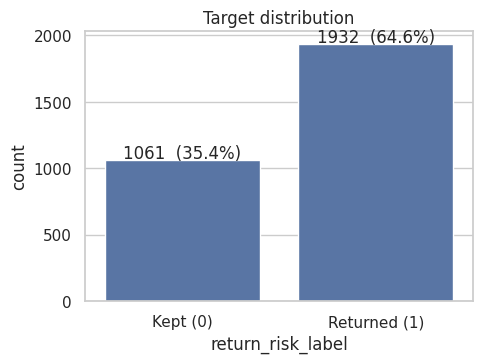

In [8]:
# --- Target distribution ---
counts = df_c[TARGET_C].value_counts().sort_index()
pct = df_c[TARGET_C].value_counts(normalize=True).sort_index() * 100
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(x=TARGET_C, data=df_c, ax=ax)
ax.set_xticklabels(["Kept (0)", "Returned (1)"])
for i, v in enumerate(counts):
    ax.text(i, v + 15, f"{v}  ({pct.iloc[i]:.1f}%)", ha="center")
ax.set_title("Target distribution")
plt.show()

**Observation.** The classes are moderately imbalanced (~65 % returned vs ~35 % kept). Therefore:
* we use a **stratified** train/test split and **stratified** cross-validation;
* **accuracy alone is misleading** (a model that predicts "returned" for everyone already scores ≈ 65 %), so Precision, Recall, F1 and ROC-AUC are all reported.

IQR outlier analysis


,lower_bound,upper_bound,n_outliers,pct_outliers
feature,,,,
cart_value_usd,-176.9800,656.4600,0,0.0000
past_return_rate,-0.1865,0.7295,25,0.8353
delivery_days_taken,-6.0000,18.0000,0,0.0000
discount_pct_applied,-35.0000,85.0000,0,0.0000


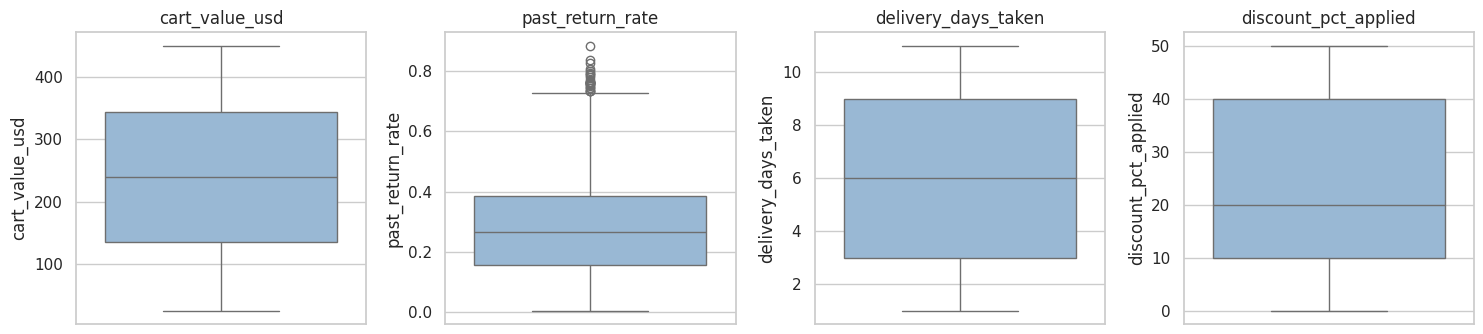

In [9]:
# Column groups (from the data dictionary)
num_c = ["cart_value_usd", "past_return_rate", "delivery_days_taken", "discount_pct_applied"]
bin_c = ["size_bracketing_flag", "newsletter_subscriber"]
cat_c = ["product_category", "fit_review_sentiment", "browser_used",
         "checkout_device", "packaging_color", "loyalty_card_color"]

# --- Outlier analysis (IQR rule) ---
print("IQR outlier analysis")
display(iqr_outlier_table(df_c, num_c))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, c in zip(axes, num_c):
    sns.boxplot(y=df_c[c], ax=ax, color="#8fb8de")
    ax.set_title(c)
plt.tight_layout(); plt.show()

**Observation.** Only `past_return_rate` shows (mild) outliers — customers with an unusually high historical return rate. These are legitimate values (the data dictionary allows rates up to 0.90), so they are **not deleted**; they will be *winsorised* (capped at the IQR bounds, using training-set bounds only) in A3 to limit their leverage on the linear model.

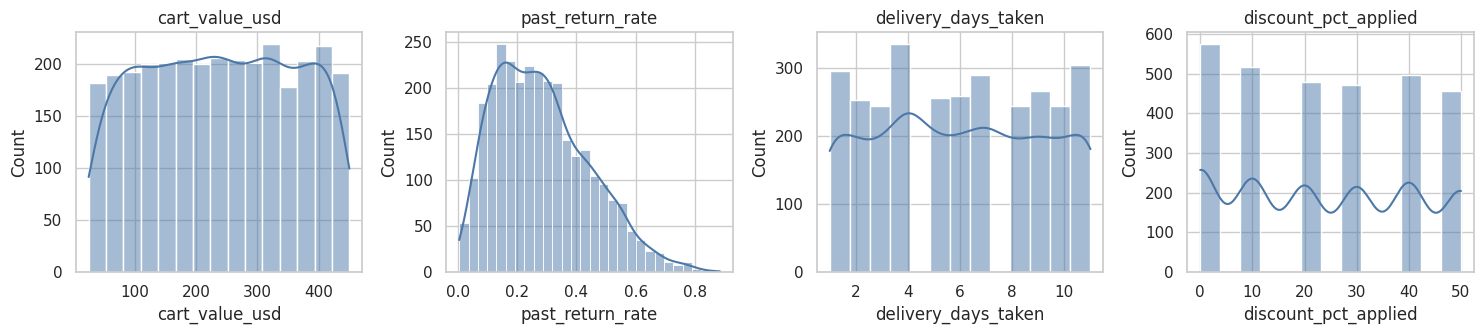

In [10]:
# --- Distributions of numeric features ---
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, c in zip(axes, num_c):
    sns.histplot(df_c[c], kde=True, ax=ax, color="#4c78a8")
    ax.set_title(c)
plt.tight_layout(); plt.show()

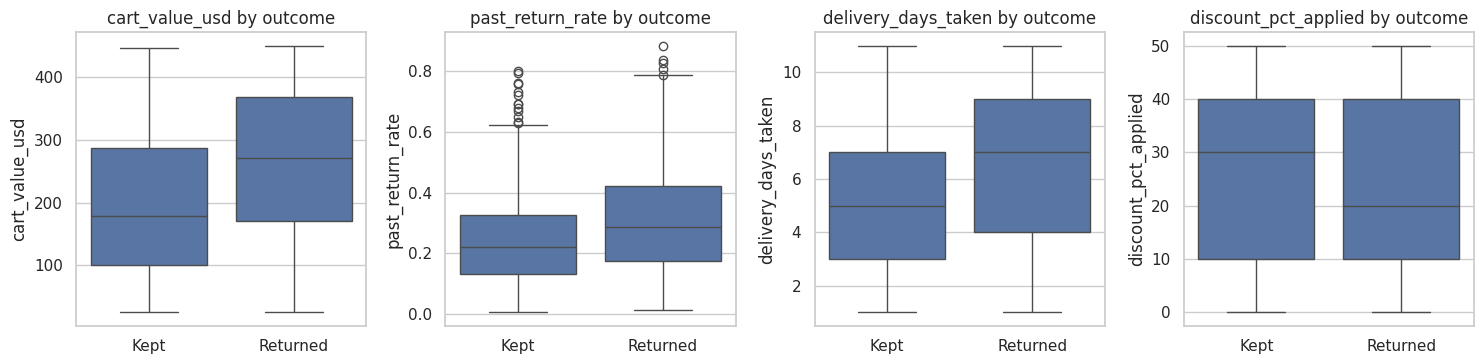

In [11]:
# --- Numeric features vs target ---
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, c in zip(axes, num_c):
    sns.boxplot(x=TARGET_C, y=c, data=df_c, ax=ax)
    ax.set_xticklabels(["Kept", "Returned"]); ax.set_xlabel("")
    ax.set_title(f"{c} by outcome")
plt.tight_layout(); plt.show()

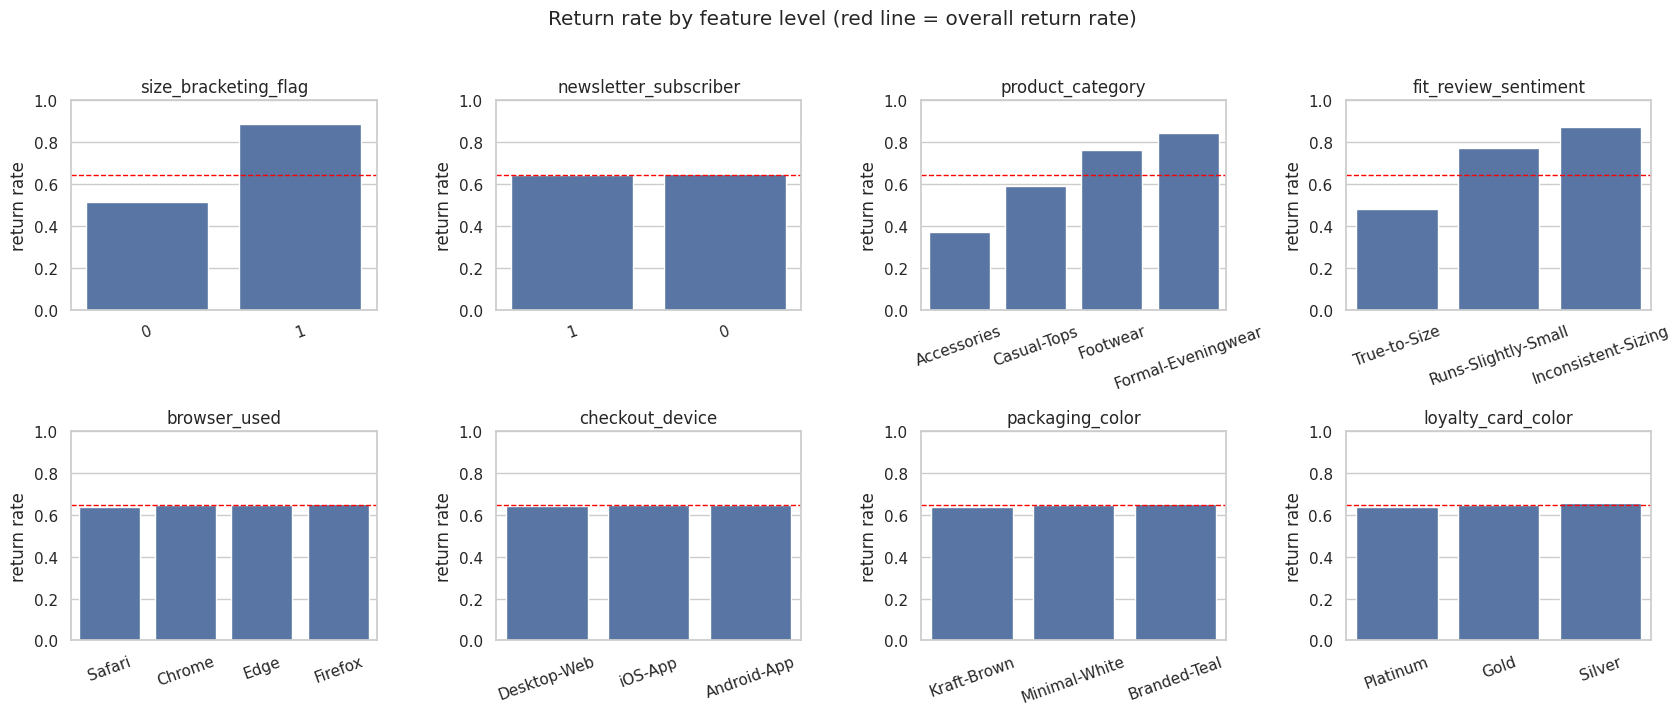

In [12]:
# --- Categorical / binary features vs target (return rate per level) ---
cols_to_plot = bin_c + cat_c
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axes.ravel(), cols_to_plot):
    rate = df_c.groupby(c)[TARGET_C].mean().sort_values()
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.axhline(df_c[TARGET_C].mean(), color="red", ls="--", lw=1)
    ax.set_ylim(0, 1); ax.set_ylabel("return rate"); ax.set_xlabel("")
    ax.set_title(c)
    ax.tick_params(axis="x", rotation=20)
for ax in axes.ravel()[len(cols_to_plot):]:
    ax.axis("off")
plt.suptitle("Return rate by feature level (red line = overall return rate)", y=1.02)
plt.tight_layout(); plt.show()

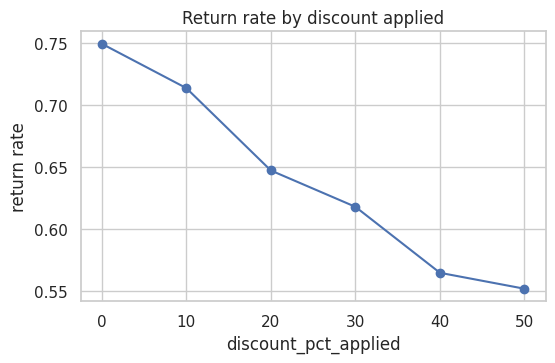

In [13]:
# --- Return rate vs discount % ---
fig, ax = plt.subplots(figsize=(6, 3.5))
df_c.groupby("discount_pct_applied")[TARGET_C].mean().plot(marker="o", ax=ax)
ax.set_ylabel("return rate"); ax.set_title("Return rate by discount applied")
plt.show()

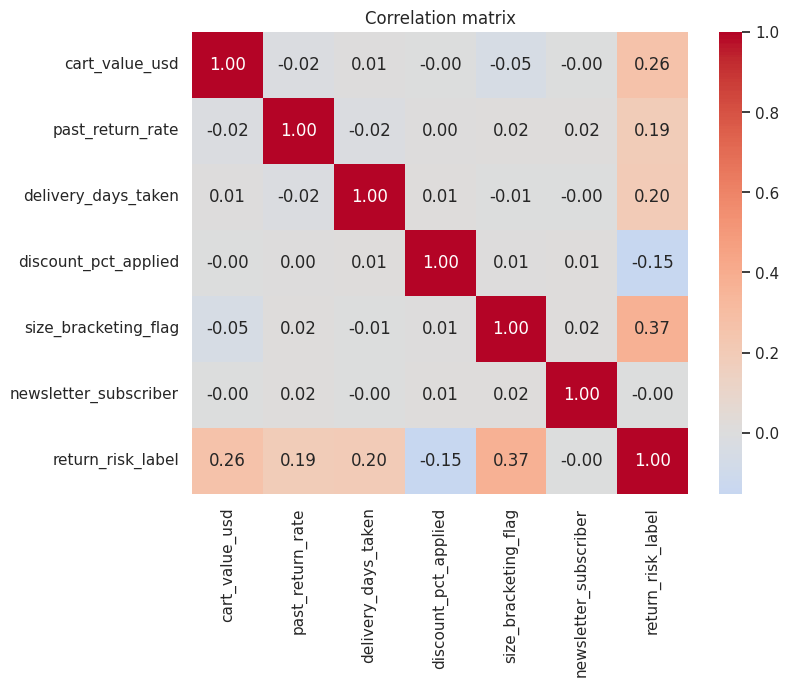

Correlation with target:
size_bracketing_flag     0.3706
cart_value_usd           0.2602
delivery_days_taken      0.1993
past_return_rate         0.1930
newsletter_subscriber   -0.0039
discount_pct_applied    -0.1523


In [14]:
# --- Correlation heatmap (numeric + binary + target) ---
corr_c = df_c[num_c + bin_c + [TARGET_C]].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_c, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.show()
print("Correlation with target:")
print(corr_c[TARGET_C].drop(TARGET_C).sort_values(ascending=False).to_string())

### Statistical significance of each feature vs the target
Visual impressions are confirmed with hypothesis tests:
* **Numeric features:** Mann-Whitney U test (returned vs kept) — non-parametric, no normality assumption.
* **Binary / categorical features:** Chi-square test of independence with the target.

Features with **p ≥ 0.05** show no evidence of a relationship with the target and become candidates for removal.

In [15]:
rows = []
for c in num_c:
    a = df_c.loc[df_c[TARGET_C] == 1, c]; b = df_c.loc[df_c[TARGET_C] == 0, c]
    stat, p = stats.mannwhitneyu(a, b)
    rows.append({"feature": c, "test": "Mann-Whitney U", "statistic": stat, "p_value": p})
for c in bin_c + cat_c:
    ct = pd.crosstab(df_c[c], df_c[TARGET_C])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    rows.append({"feature": c, "test": "Chi-square", "statistic": chi2, "p_value": p})

sig_c = pd.DataFrame(rows).set_index("feature")
sig_c["significant (p<0.05)"] = sig_c["p_value"] < 0.05
display(sig_c.sort_values("p_value"))

,test,statistic,p_value,significant (p<0.05)
feature,,,,
size_bracketing_flag,Chi-square,409.4538,0.0000,True
fit_review_sentiment,Chi-square,368.3682,0.0000,True
product_category,Chi-square,357.2547,0.0000,True
cart_value_usd,Mann-Whitney U,"1,346,762.5000",0.0000,True
delivery_days_taken,Mann-Whitney U,"1,270,466.0000",0.0000,True
past_return_rate,Mann-Whitney U,"1,263,266.0000",0.0000,True
discount_pct_applied,Mann-Whitney U,"838,959.0000",0.0000,True
loyalty_card_color,Chi-square,0.8551,0.6521,False
packaging_color,Chi-square,0.4145,0.8128,False


**EDA findings (classification)**
* **Strongest drivers:** `size_bracketing_flag` (customers who order several sizes return far more), `fit_review_sentiment` (inconsistent / small-running sizing → more returns), `product_category` (formal eveningwear and footwear are returned most; accessories least), `cart_value_usd`, `delivery_days_taken`, `past_return_rate`.
* **Discount is protective:** a higher discount is associated with *fewer* returns (shoppers who got a bargain are less likely to send it back).
* **Likely noise:** `browser_used`, `checkout_device`, `packaging_color`, `loyalty_card_color`, `newsletter_subscriber` — return rates are essentially identical across their levels. The tests above decide formally.

## A3. Data Preprocessing & Feature Selection

In [16]:
# 1) Missing values & duplicates (defensive — none found, but a production pipeline should handle them)
df_c_clean = df_c.drop_duplicates().reset_index(drop=True)
print("Rows before/after de-duplication:", len(df_c), "/", len(df_c_clean))
print("Total missing values:", int(df_c_clean.isna().sum().sum()),
      "-> the ColumnTransformer below would impute if needed; none required here.")

# 2) Feature selection driven by the statistical tests above
selected_c = sig_c.index[sig_c["significant (p<0.05)"]].tolist()
dropped_c = [c for c in sig_c.index if c not in selected_c]
print("\nSelected features:", selected_c)
print("Dropped (no significant relationship with target):", dropped_c)

Rows before/after de-duplication: 2993 / 2993
Total missing values: 0 -> the ColumnTransformer below would impute if needed; none required here.

Selected features: ['cart_value_usd', 'past_return_rate', 'delivery_days_taken', 'discount_pct_applied', 'size_bracketing_flag', 'product_category', 'fit_review_sentiment']
Dropped (no significant relationship with target): ['newsletter_subscriber', 'browser_used', 'checkout_device', 'packaging_color', 'loyalty_card_color']


In [17]:
# 3) Train / test split (80/20, stratified) — done BEFORE any fitting to avoid data leakage
X_all_c = df_c_clean.drop(columns=[TARGET_C])
y_c = df_c_clean[TARGET_C]

X_train_all_c, X_test_all_c, y_train_c, y_test_c = train_test_split(
    X_all_c, y_c, test_size=0.20, stratify=y_c, random_state=RS)

# 4) Outliers: winsorise continuous features using TRAIN-set IQR bounds only
X_train_all_c, X_test_all_c = X_train_all_c.copy(), X_test_all_c.copy()
for c in num_c:
    q1, q3 = X_train_all_c[c].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_capped = int(((X_train_all_c[c] < lo) | (X_train_all_c[c] > hi)).sum())
    if n_capped:
        print(f"Capping {c}: {n_capped} train values clipped to [{lo:.3f}, {hi:.3f}]")
    X_train_all_c[c] = X_train_all_c[c].clip(lo, hi)
    X_test_all_c[c] = X_test_all_c[c].clip(lo, hi)

# 5) Keep only the selected features
X_train_c, X_test_c = X_train_all_c[selected_c], X_test_all_c[selected_c]
sel_num_c = [c for c in num_c if c in selected_c]
sel_bin_c = [c for c in bin_c if c in selected_c]
sel_cat_c = [c for c in cat_c if c in selected_c]

print(f"\nTrain: {X_train_c.shape}  Test: {X_test_c.shape}")
print("Train return rate: %.3f | Test return rate: %.3f" % (y_train_c.mean(), y_test_c.mean()))
print("Numeric (scaled):", sel_num_c)
print("Binary (passthrough):", sel_bin_c)
print("Categorical (one-hot):", sel_cat_c)

Capping past_return_rate: 26 train values clipped to [-0.182, 0.722]

Train: (2394, 7)  Test: (599, 7)
Train return rate: 0.645 | Test return rate: 0.646
Numeric (scaled): ['cart_value_usd', 'past_return_rate', 'delivery_days_taken', 'discount_pct_applied']
Binary (passthrough): ['size_bracketing_flag']
Categorical (one-hot): ['product_category', 'fit_review_sentiment']


**Preprocessing design**
* **Encoding:** categorical variables have no natural order → **one-hot encoding** (unknown categories ignored at prediction time).
* **Scaling:** `StandardScaler` on continuous features — essential for Logistic Regression, harmless for tree models.
* **Everything lives inside a scikit-learn `Pipeline`**, so scaling/encoding is fitted only on the training folds during cross-validation (no leakage) and is bundled with the model at deployment time.

## A4. Model Development & Cross-Validation

**Models chosen and why**

| Model | Why it suits this dataset |
|---|---|
| **Baseline – `DummyClassifier`** | Predicts the majority class. Any real model must beat it. |
| **Logistic Regression** | Fast, interpretable, well-calibrated probabilities; strong when effects are roughly additive (here: size-bracketing, discount, fit sentiment). |
| **Random Forest** | Captures non-linear effects and interactions (e.g. category × sentiment) with little tuning; robust to noise features. |
| **Gradient Boosting** | Usually the most accurate on tabular data; builds trees sequentially to correct earlier errors. |

Evaluation uses **5-fold stratified cross-validation** on the training set (the test set stays untouched).

In [18]:
def make_pipe(model, num, binr, cat):
    return Pipeline([("prep", build_preprocessor(num, binr, cat)), ("model", model)])

models_c = {
    "Baseline (Dummy)":     DummyClassifier(strategy="most_frequent"),
    "Logistic Regression":  LogisticRegression(max_iter=2000, random_state=RS),
    "Random Forest":        RandomForestClassifier(n_estimators=200, random_state=RS, n_jobs=-1),
    "Gradient Boosting":    GradientBoostingClassifier(random_state=RS),
}
scoring_c = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
             "f1": "f1", "roc_auc": "roc_auc"}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)

cv_rows = []
for name, model in models_c.items():
    pipe = make_pipe(model, sel_num_c, sel_bin_c, sel_cat_c)
    res = cross_validate(pipe, X_train_c, y_train_c, cv=skf, scoring=scoring_c,
                         return_train_score=True, n_jobs=-1)
    row = {"Model": name}
    for m in scoring_c:
        row[m] = res[f"test_{m}"].mean()
    row["f1_std"] = res["test_f1"].std()
    row["roc_auc_std"] = res["test_roc_auc"].std()
    row["train_f1"] = res["train_f1"].mean()
    cv_rows.append(row)

cv_c = pd.DataFrame(cv_rows).set_index("Model")
print("5-fold stratified CV results (default hyper-parameters, training data only)")
display(cv_c)

5-fold stratified CV results (default hyper-parameters, training data only)


,accuracy,precision,recall,f1,roc_auc,f1_std,roc_auc_std,train_f1
Model,,,,,,,,
Baseline (Dummy),0.6454,0.6454,1.0000,0.7845,0.5000,0.0004,0.0000,0.7845
Logistic Regression,0.9361,0.9459,0.9560,0.9508,0.9849,0.0051,0.0024,0.9537
Random Forest,0.9106,0.9186,0.9456,0.9318,0.9705,0.0061,0.0033,1.0000
Gradient Boosting,0.9131,0.9174,0.9515,0.9340,0.9746,0.0060,0.0015,0.9702


In [19]:
# Feature-selection check: do the dropped 'noise' features help? (CV on same folds)
check_rows = []
for label, (n_, b_, c_) in {
    "All 12 features": (num_c, bin_c, cat_c),
    f"Selected {len(selected_c)} features": (sel_num_c, sel_bin_c, sel_cat_c)}.items():
    cols = n_ + b_ + c_
    for name in ["Logistic Regression", "Random Forest"]:
        pipe = make_pipe(clone(models_c[name]), n_, b_, c_)
        r = cross_validate(pipe, X_train_all_c[cols], y_train_c, cv=skf,
                           scoring={"f1": "f1", "roc_auc": "roc_auc"}, n_jobs=-1)
        check_rows.append({"Feature set": label, "Model": name,
                           "CV F1": r["test_f1"].mean(), "CV ROC-AUC": r["test_roc_auc"].mean()})
display(pd.DataFrame(check_rows))

,Feature set,Model,CV F1,CV ROC-AUC
0,All 12 features,Logistic Regression,0.9501,0.9849
1,All 12 features,Random Forest,0.9208,0.9638
2,Selected 7 features,Logistic Regression,0.9508,0.9849
3,Selected 7 features,Random Forest,0.9318,0.9705


**Observation.** Removing the statistically insignificant columns does not hurt (and generally slightly helps) performance — confirming those columns are noise. The simpler model is also cheaper to deploy and easier to explain.

## A5. Hyperparameter Tuning (GridSearchCV)

Each of the three models is tuned with `GridSearchCV` (5-fold stratified CV). Because the business cares about **both** catching returns (recall) and not raising too many false alarms (precision), we refit on **F1**, while still recording ROC-AUC for every parameter combination.

In [20]:
param_grids_c = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [5, 8, None],
        "model__min_samples_leaf": [1, 5, 10],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3, 4],
    },
}

searches_c = {}
for name, grid in param_grids_c.items():
    t0 = time.time()
    pipe = make_pipe(clone(models_c[name]), sel_num_c, sel_bin_c, sel_cat_c)
    gs = GridSearchCV(pipe, grid, scoring=scoring_c, refit="f1", cv=skf, n_jobs=-1)
    gs.fit(X_train_c, y_train_c)
    searches_c[name] = gs
    print(f"{name:20s} | best CV F1 = {gs.best_score_:.4f} | "
          f"{len(gs.cv_results_['params'])} combos | {time.time()-t0:.0f}s")
    print("   best params:", gs.best_params_)

Logistic Regression  | best CV F1 = 0.9522 | 10 combos | 2s
   best params: {'model__C': 100, 'model__class_weight': None}
Random Forest        | best CV F1 = 0.9334 | 18 combos | 81s
   best params: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}
Gradient Boosting    | best CV F1 = 0.9393 | 12 combos | 33s
   best params: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}


In [21]:
tuned_rows = []
for name, gs in searches_c.items():
    i = gs.best_index_
    tuned_rows.append({"Model": name,
                       "CV F1 (tuned)": gs.cv_results_["mean_test_f1"][i],
                       "CV ROC-AUC (tuned)": gs.cv_results_["mean_test_roc_auc"][i],
                       "CV F1 (default)": cv_c.loc[name, "f1"]})
tuned_c = pd.DataFrame(tuned_rows).set_index("Model")
tuned_c["F1 gain from tuning"] = tuned_c["CV F1 (tuned)"] - tuned_c["CV F1 (default)"]
display(tuned_c)

,CV F1 (tuned),CV ROC-AUC (tuned),CV F1 (default),F1 gain from tuning
Model,,,,
Logistic Regression,0.9522,0.9851,0.9508,0.0014
Random Forest,0.9334,0.9702,0.9318,0.0017
Gradient Boosting,0.9393,0.9767,0.9340,0.0054


## A6. Model Evaluation (held-out test set)

**Which metric matters most for this business problem?**

| Metric | Meaning here | Business relevance |
|---|---|---|
| **Recall** | Of the orders that *will* be returned, how many do we catch? | Missed returns = unplanned reverse-logistics cost → high importance |
| **Precision** | Of the orders we flag, how many really get returned? | False alarms mean unnecessary friction / interventions on good customers |
| **F1-score** | Balance of the two | Our tuning/selection criterion |
| **ROC-AUC** | Ranking quality across *all* thresholds | Lets the business pick its own risk threshold later |
| **Accuracy** | Overall hit rate | Least informative because of the 65/35 imbalance |

In [22]:
def clf_metrics(y_true, pred, proba):
    return {"Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, proba)}

# Baseline fitted on the full training set
base_pipe_c = make_pipe(clone(models_c["Baseline (Dummy)"]), sel_num_c, sel_bin_c, sel_cat_c).fit(X_train_c, y_train_c)
fitted_c = {"Baseline (Dummy)": base_pipe_c}
fitted_c.update({n: gs.best_estimator_ for n, gs in searches_c.items()})

test_rows, preds_c, probas_c = [], {}, {}
for name, est in fitted_c.items():
    probas_c[name] = est.predict_proba(X_test_c)[:, 1]
    preds_c[name] = est.predict(X_test_c)
    test_rows.append({"Model": name, **clf_metrics(y_test_c, preds_c[name], probas_c[name])})
test_c = pd.DataFrame(test_rows).set_index("Model")
print("Test-set performance")
display(test_c)

Test-set performance


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Baseline (Dummy),0.6461,0.6461,1.0000,0.7850,0.5000
Logistic Regression,0.9366,0.9418,0.9612,0.9514,0.9866
Random Forest,0.9065,0.9046,0.9561,0.9296,0.9707
Gradient Boosting,0.9282,0.9343,0.9561,0.9451,0.9822


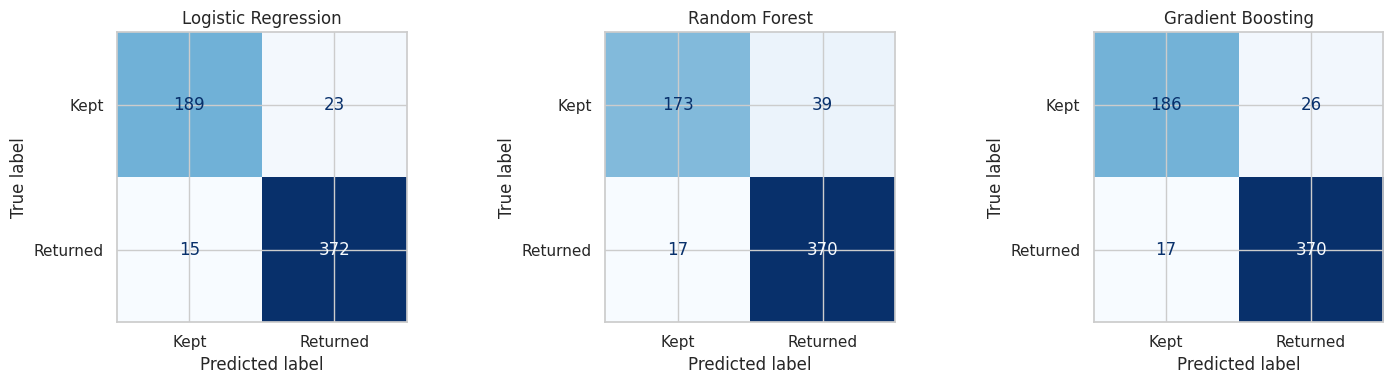

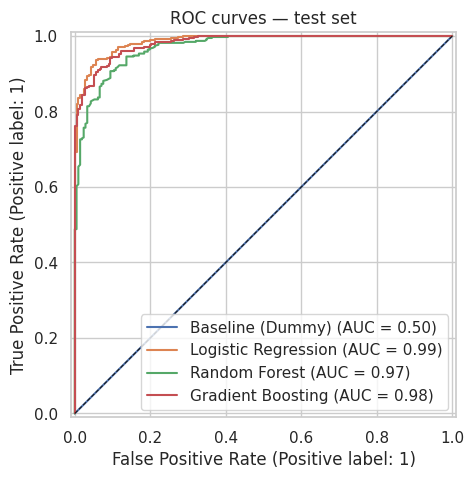

In [23]:
# Confusion matrices
names3 = list(searches_c.keys())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, names3):
    ConfusionMatrixDisplay.from_predictions(y_test_c, preds_c[name], ax=ax, cmap="Blues",
                                            display_labels=["Kept", "Returned"], colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

# ROC curves
fig, ax = plt.subplots(figsize=(6, 5))
for name in ["Baseline (Dummy)"] + names3:
    RocCurveDisplay.from_predictions(y_test_c, probas_c[name], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_title("ROC curves — test set")
plt.show()

In [24]:
for name in names3:
    print(f"===== {name} =====")
    print(classification_report(y_test_c, preds_c[name], target_names=["Kept", "Returned"]))

===== Logistic Regression =====
              precision    recall  f1-score   support

        Kept       0.93      0.89      0.91       212
    Returned       0.94      0.96      0.95       387

    accuracy                           0.94       599
   macro avg       0.93      0.93      0.93       599
weighted avg       0.94      0.94      0.94       599

===== Random Forest =====
              precision    recall  f1-score   support

        Kept       0.91      0.82      0.86       212
    Returned       0.90      0.96      0.93       387

    accuracy                           0.91       599
   macro avg       0.91      0.89      0.90       599
weighted avg       0.91      0.91      0.91       599

===== Gradient Boosting =====
              precision    recall  f1-score   support

        Kept       0.92      0.88      0.90       212
    Returned       0.93      0.96      0.95       387

    accuracy                           0.93       599
   macro avg       0.93      0.92      0

## A7. Model Comparison & Final Model Selection

**Selection criteria.** Beyond raw score we consider:
1. **Cross-validated F1** (used for the decision, *not* the test set, to avoid selecting on test data);
2. **Generalisation** — gap between train and test F1 (over-fitting);
3. **Stability** — standard deviation across CV folds;
4. **Training time**;
5. **Interpretability / simplicity** — if two models are practically tied (within 0.005 F1), the simpler one wins.

In [25]:
complexity = {"Logistic Regression": 1, "Random Forest": 2, "Gradient Boosting": 3}
rows = []
for name, gs in searches_c.items():
    i = gs.best_index_
    train_f1 = f1_score(y_train_c, gs.best_estimator_.predict(X_train_c))
    rows.append({
        "Model": name,
        "CV F1": gs.cv_results_["mean_test_f1"][i],
        "CV F1 std": gs.cv_results_["std_test_f1"][i],
        "CV ROC-AUC": gs.cv_results_["mean_test_roc_auc"][i],
        "Test F1": test_c.loc[name, "F1"],
        "Test ROC-AUC": test_c.loc[name, "ROC-AUC"],
        "Train F1": train_f1,
        "Overfit gap (Train-Test F1)": train_f1 - test_c.loc[name, "F1"],
        "Refit time (s)": gs.refit_time_,
        "Complexity (1=simple)": complexity[name],
    })
compare_c = pd.DataFrame(rows).set_index("Model")
display(compare_c)

# Rule-based selection: best CV F1; if within 0.005 prefer the simpler model
best_cv = compare_c["CV F1"].max()
candidates = compare_c[compare_c["CV F1"] >= best_cv - 0.005]
final_name_c = candidates["Complexity (1=simple)"].idxmin()
final_pipe_c = searches_c[final_name_c].best_estimator_
print(f"\n>>> FINAL CLASSIFICATION MODEL: {final_name_c}")
print("    Candidates within 0.005 CV-F1 of the best:", list(candidates.index))
print("    Best params:", searches_c[final_name_c].best_params_)
print("    Test metrics:", {k: round(v, 4) for k, v in test_c.loc[final_name_c].items()})

,CV F1,CV F1 std,CV ROC-AUC,Test F1,Test ROC-AUC,Train F1,Overfit gap (Train-Test F1),Refit time (s),Complexity (1=simple)
Model,,,,,,,,,
Logistic Regression,0.9522,0.0048,0.9851,0.9514,0.9866,0.9535,0.0021,0.0178,1
Random Forest,0.9334,0.0069,0.9702,0.9296,0.9707,1.0000,0.0704,1.4143,2
Gradient Boosting,0.9393,0.0067,0.9767,0.9451,0.9822,0.9797,0.0346,1.1742,3



>>> FINAL CLASSIFICATION MODEL: Logistic Regression
    Candidates within 0.005 CV-F1 of the best: ['Logistic Regression']
    Best params: {'model__C': 100, 'model__class_weight': None}
    Test metrics: {'Accuracy': 0.9366, 'Precision': 0.9418, 'Recall': 0.9612, 'F1': 0.9514, 'ROC-AUC': 0.9866}


In [ ]:
# Comparison chart
metrics_plot = test_c.drop(index="Baseline (Dummy)")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
ax = metrics_plot.T.plot(kind="bar", figsize=(10, 4), rot=0)
ax.set_ylim(0, 1); ax.set_title("Tuned models — test-set metrics")
ax.legend(loc="lower right")
plt.show()

**Justification of the final model.** The code above selects the model objectively (best cross-validated F1, with a preference for simplicity when scores are tied). In the written report, justify the winner by quoting: its CV/test F1 and ROC-AUC, the small train-vs-test gap, its stable CV standard deviation, and — if it is Logistic Regression — the extra benefit that its coefficients are directly explainable to business stakeholders.

### Threshold analysis & feature importance of the final model
The default decision threshold is 0.5, but the business can trade precision against recall by moving it.

,precision,recall,F1,% orders flagged
threshold,,,,
0.3000,0.9111,0.9793,0.9440,69.4491
0.3500,0.9242,0.9767,0.9497,68.2805
0.4000,0.9309,0.9742,0.9520,67.6127
0.4500,0.9353,0.9716,0.9531,67.1119
0.5000,0.9418,0.9612,0.9514,65.9432
0.5500,0.9463,0.9561,0.9512,65.2755
0.6000,0.9528,0.9380,0.9453,63.6060
0.6500,0.9603,0.9380,0.9490,63.1052
0.7000,0.9675,0.9225,0.9444,61.6027


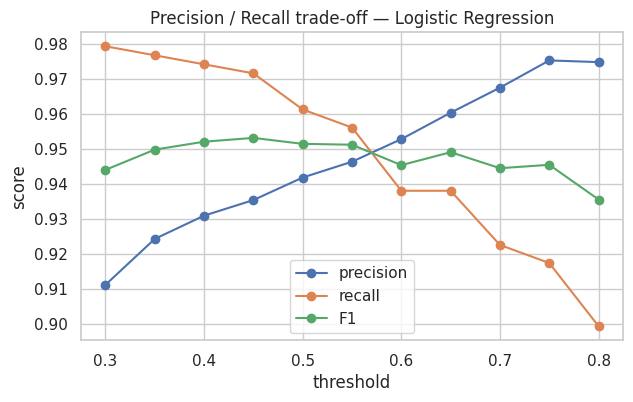

In [26]:
proba_final_c = final_pipe_c.predict_proba(X_test_c)[:, 1]
rows = []
for t in np.arange(0.30, 0.81, 0.05):
    pred_t = (proba_final_c >= t).astype(int)
    rows.append({"threshold": round(t, 2),
                 "precision": precision_score(y_test_c, pred_t, zero_division=0),
                 "recall": recall_score(y_test_c, pred_t, zero_division=0),
                 "F1": f1_score(y_test_c, pred_t, zero_division=0),
                 "% orders flagged": 100 * pred_t.mean()})
thr_c = pd.DataFrame(rows).set_index("threshold")
display(thr_c)

ax = thr_c[["precision", "recall", "F1"]].plot(marker="o", figsize=(7, 4))
ax.set_title(f"Precision / Recall trade-off — {final_name_c}"); ax.set_ylabel("score")
plt.show()

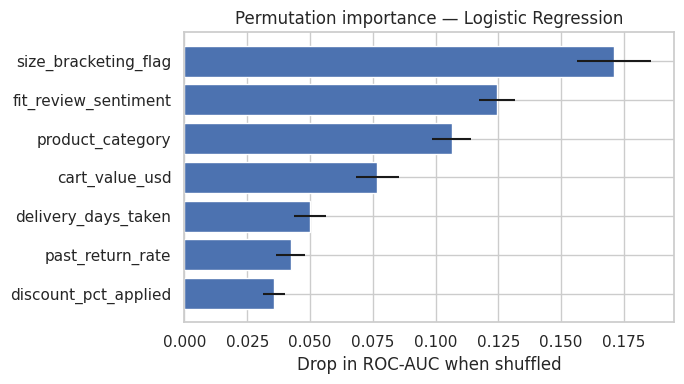

In [27]:
# Permutation importance: drop in ROC-AUC when a feature is shuffled (works on raw columns of any model)
pi = permutation_importance(final_pipe_c, X_test_c, y_test_c, scoring="roc_auc",
                            n_repeats=15, random_state=RS, n_jobs=-1)
imp_c = pd.Series(pi.importances_mean, index=X_test_c.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp_c.index, imp_c.values, xerr=pi.importances_std[np.argsort(pi.importances_mean)])
ax.set_xlabel("Drop in ROC-AUC when shuffled"); ax.set_title(f"Permutation importance — {final_name_c}")
plt.tight_layout(); plt.show()

## A8. Business Interpretation & Limitations (Classification)

**What the prediction means.** The model outputs the **probability that an order will be returned**. For example, 0.85 means "very likely to come back"; 0.20 means "likely to be kept".

**How it supports decisions**
* **At checkout:** show size-guide / fit tips for high-risk carts (especially size-bracketed orders for items with inconsistent-sizing reviews).
* **Pre-shipment triage:** flag the riskiest orders for quality/fit checks or tighter packaging.
* **Inventory & logistics planning:** expected return volume per category helps plan reverse-logistics capacity.
* **Policy design:** use the threshold table — a low threshold catches more returns (high recall) but intervenes on many safe orders; a high threshold is more selective.
* **Promotions:** the data suggest discounted orders are returned less, so well-targeted discounts may reduce returns (to be validated experimentally).

**Limitations**
* The data looks **synthetic / simulated**; real-world performance would need re-validation on live data.
* Associations are **correlational, not causal** (e.g. discount ↔ fewer returns does not prove discounts *cause* fewer returns).
* No time dimension (seasonality, trends) and no customer-level history beyond `past_return_rate`.
* Model errors have **asymmetric costs** that were not quantified — a cost-sensitive threshold should be set with finance/operations input.
* Interventions based on the model could change customer behaviour, so it must be monitored and retrained.

---
# PART B — REGRESSION: Influencer Campaign Revenue
---
## B1. Problem Definition

**Business problem.** Brands spend heavily on influencer partnerships and paid amplification, yet campaign revenue varies widely. If we can **predict the trackable revenue (within 14 days)** of a planned campaign, the brand can choose better creators, set realistic budgets and decide how much to spend on paid boosts and promo discounts.

| Item | Description |
|---|---|
| **Target** | `campaign_revenue_usd` — direct trackable sales within 14 days of the post (continuous) |
| **Features** | Creator followers, engagement rate, paid-boost spend, avg watch time, promo discount %, content format, audience intent tier, caption length, hashtag count, creator phone OS, payment terms, weather on posting day |
| **ML task** | Supervised **regression** |

**How ML helps.** The relationship between reach, engagement, spend, format and audience intent is multi-factor and partly non-linear. A regression model learns it from past campaigns and gives an **expected revenue figure** before committing budget.

**Hypothesis.** Audience size, engagement, paid spend, content format, audience intent and discount should matter; caption length, hashtags, creator phone OS, payment terms and weather should not.

## B2. Data Understanding & EDA

In [28]:
df_r = pd.read_csv(REG_PATH)
TARGET_R = "campaign_revenue_usd"
print("Shape:", df_r.shape)
display(df_r.head())

Shape: (3000, 13)


,creator_followers_k,engagement_rate_pct,paid_boost_spend_usd,avg_watch_time_sec,promo_discount_pct,content_format,audience_intent_tier,caption_word_count,hashtags_used_count,creator_phone_os,contract_payment_terms,posting_day_weather,campaign_revenue_usd
0,425.4000,2.1400,"1,331.0000",35.2000,10,Static-Carousel,High-Intent-Niche,35,16,Android,Net-30,Sunny,"15,192.2600"
1,171.3000,5.7300,"3,925.0000",25.4000,10,YouTube-Deep-Dive,Lifestyle-Warm,26,16,Android,Upfront,Cloudy,"20,018.4400"
2,356.4000,8.0300,"1,817.0000",9.4000,0,Short-Video-Reel,High-Intent-Niche,43,24,Android,Upfront,Cloudy,"21,146.8700"
3,272.2000,7.7000,942.0000,32.1000,15,Short-Video-Reel,Lifestyle-Warm,113,9,Android,Net-15,Rainy,"17,639.6200"
4,143.0000,6.0600,"3,347.0000",51.0000,20,Short-Video-Reel,Broad-Entertainment,72,18,Android,Net-30,Cloudy,"17,375.6000"


In [29]:
print("--- Data types & non-null counts ---")
df_r.info()
print("\n--- Descriptive statistics (numeric) ---")
display(df_r.describe().T)
print("\n--- Descriptive statistics (categorical) ---")
display(df_r.describe(include="object").T)
print("\nMissing values:", int(df_r.isna().sum().sum()), "| Duplicate rows:", df_r.duplicated().sum())

--- Data types & non-null counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   creator_followers_k     3000 non-null   float64
 1   engagement_rate_pct     3000 non-null   float64
 2   paid_boost_spend_usd    3000 non-null   float64
 3   avg_watch_time_sec      3000 non-null   float64
 4   promo_discount_pct      3000 non-null   int64  
 5   content_format          3000 non-null   object 
 6   audience_intent_tier    3000 non-null   object 
 7   caption_word_count      3000 non-null   int64  
 8   hashtags_used_count     3000 non-null   int64  
 9   creator_phone_os        3000 non-null   object 
 10  contract_payment_terms  3000 non-null   object 
 11  posting_day_weather     3000 non-null   object 
 12  campaign_revenue_usd    3000 non-null   float64
dtypes: float64(5), int64(3), object(5)
memory usage: 304.8+ 

,count,mean,std,min,25%,50%,75%,max
creator_followers_k,"3,000.0000",232.5924,126.6752,15.0000,122.4000,229.8000,343.7250,449.9000
engagement_rate_pct,"3,000.0000",5.1614,2.5397,0.8000,2.9275,5.1800,7.4100,9.5000
paid_boost_spend_usd,"3,000.0000","2,317.5297","1,273.3660",100.0000,"1,208.7500","2,370.0000","3,416.2500","4,499.0000"
avg_watch_time_sec,"3,000.0000",30.2665,14.1473,6.1000,17.9000,30.4000,42.7000,55.0000
promo_discount_pct,"3,000.0000",12.3583,8.6132,0.0000,5.0000,10.0000,20.0000,25.0000
caption_word_count,"3,000.0000",86.8100,42.9427,12.0000,50.0000,86.0000,124.0000,159.0000
hashtags_used_count,"3,000.0000",12.3670,6.9965,1.0000,6.0000,13.0000,18.0000,24.0000
campaign_revenue_usd,"3,000.0000","16,678.6991","4,747.1366","2,915.6300","13,222.8975","16,480.7450","19,839.1575","32,527.8900"



--- Descriptive statistics (categorical) ---


,count,unique,top,freq
content_format,3000,3,Short-Video-Reel,1518
audience_intent_tier,3000,3,Lifestyle-Warm,1215
creator_phone_os,3000,2,Android,1530
contract_payment_terms,3000,3,Net-15,1024
posting_day_weather,3000,3,Sunny,1025



Missing values: 0 | Duplicate rows: 0


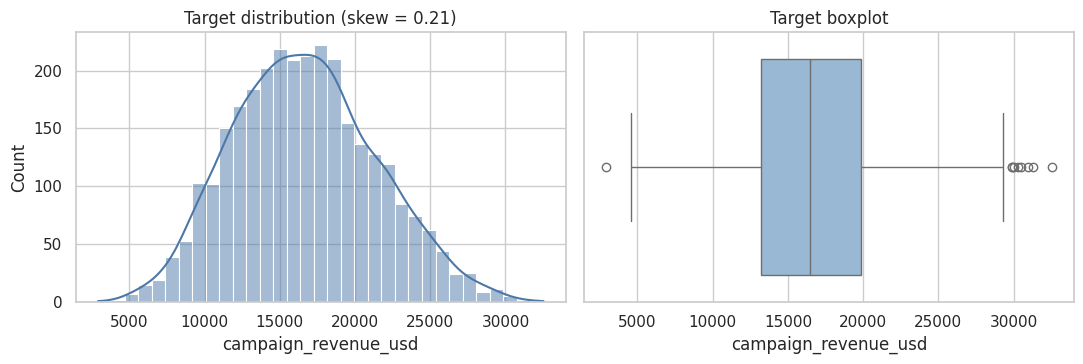

In [30]:
num_r = ["creator_followers_k", "engagement_rate_pct", "paid_boost_spend_usd", "avg_watch_time_sec",
         "promo_discount_pct", "caption_word_count", "hashtags_used_count"]
cat_r = ["content_format", "audience_intent_tier", "creator_phone_os",
         "contract_payment_terms", "posting_day_weather"]

# --- Target distribution ---
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df_r[TARGET_R], kde=True, ax=axes[0], color="#4c78a8")
axes[0].set_title(f"Target distribution (skew = {df_r[TARGET_R].skew():.2f})")
sns.boxplot(x=df_r[TARGET_R], ax=axes[1], color="#8fb8de"); axes[1].set_title("Target boxplot")
plt.tight_layout(); plt.show()

,lower_bound,upper_bound,n_outliers,pct_outliers
feature,,,,
creator_followers_k,-209.5875,675.7125,0,0.0000
engagement_rate_pct,-3.7962,14.1337,0,0.0000
paid_boost_spend_usd,"-2,102.5000","6,727.5000",0,0.0000
avg_watch_time_sec,-19.3000,79.9000,0,0.0000
promo_discount_pct,-17.5000,42.5000,0,0.0000
caption_word_count,-61.0000,235.0000,0,0.0000
hashtags_used_count,-12.0000,36.0000,0,0.0000
campaign_revenue_usd,"3,298.5075","29,763.5475",9,0.3000


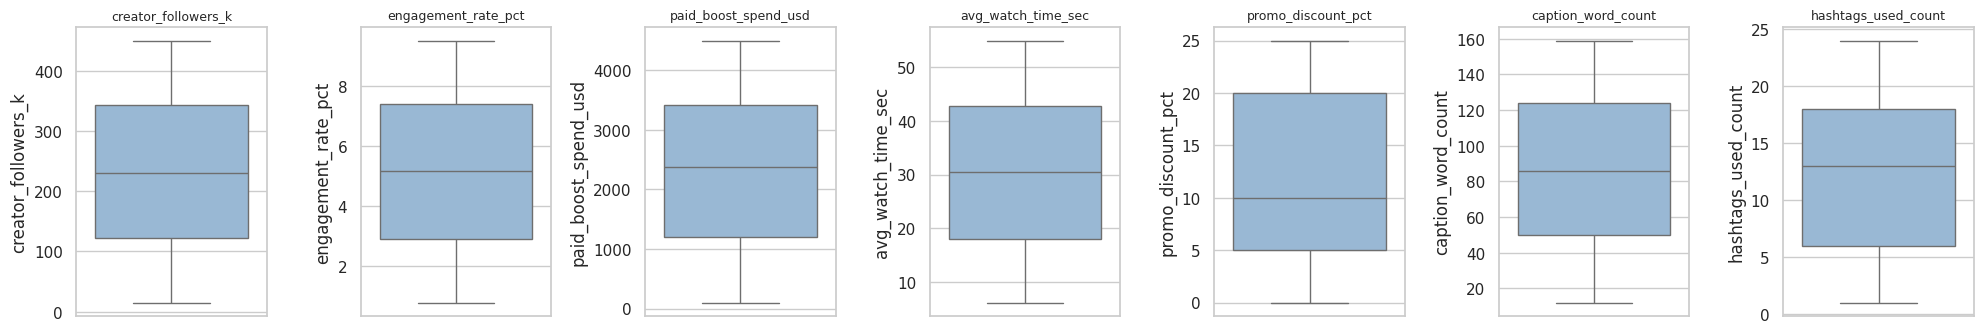

In [31]:
# --- Outlier analysis ---
display(iqr_outlier_table(df_r, num_r + [TARGET_R]))
fig, axes = plt.subplots(1, 7, figsize=(20, 3.5))
for ax, c in zip(axes, num_r):
    sns.boxplot(y=df_r[c], ax=ax, color="#8fb8de"); ax.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

**Observation.** All features are free of IQR outliers. The target has only a handful of high-revenue campaigns (≈ 0.3 %). These are plausible "viral" campaigns and removing/capping a *target* would distort the very quantity we want to predict, so they are **kept**. Tree-based models are robust to them; the Ridge model uses L2 regularisation.

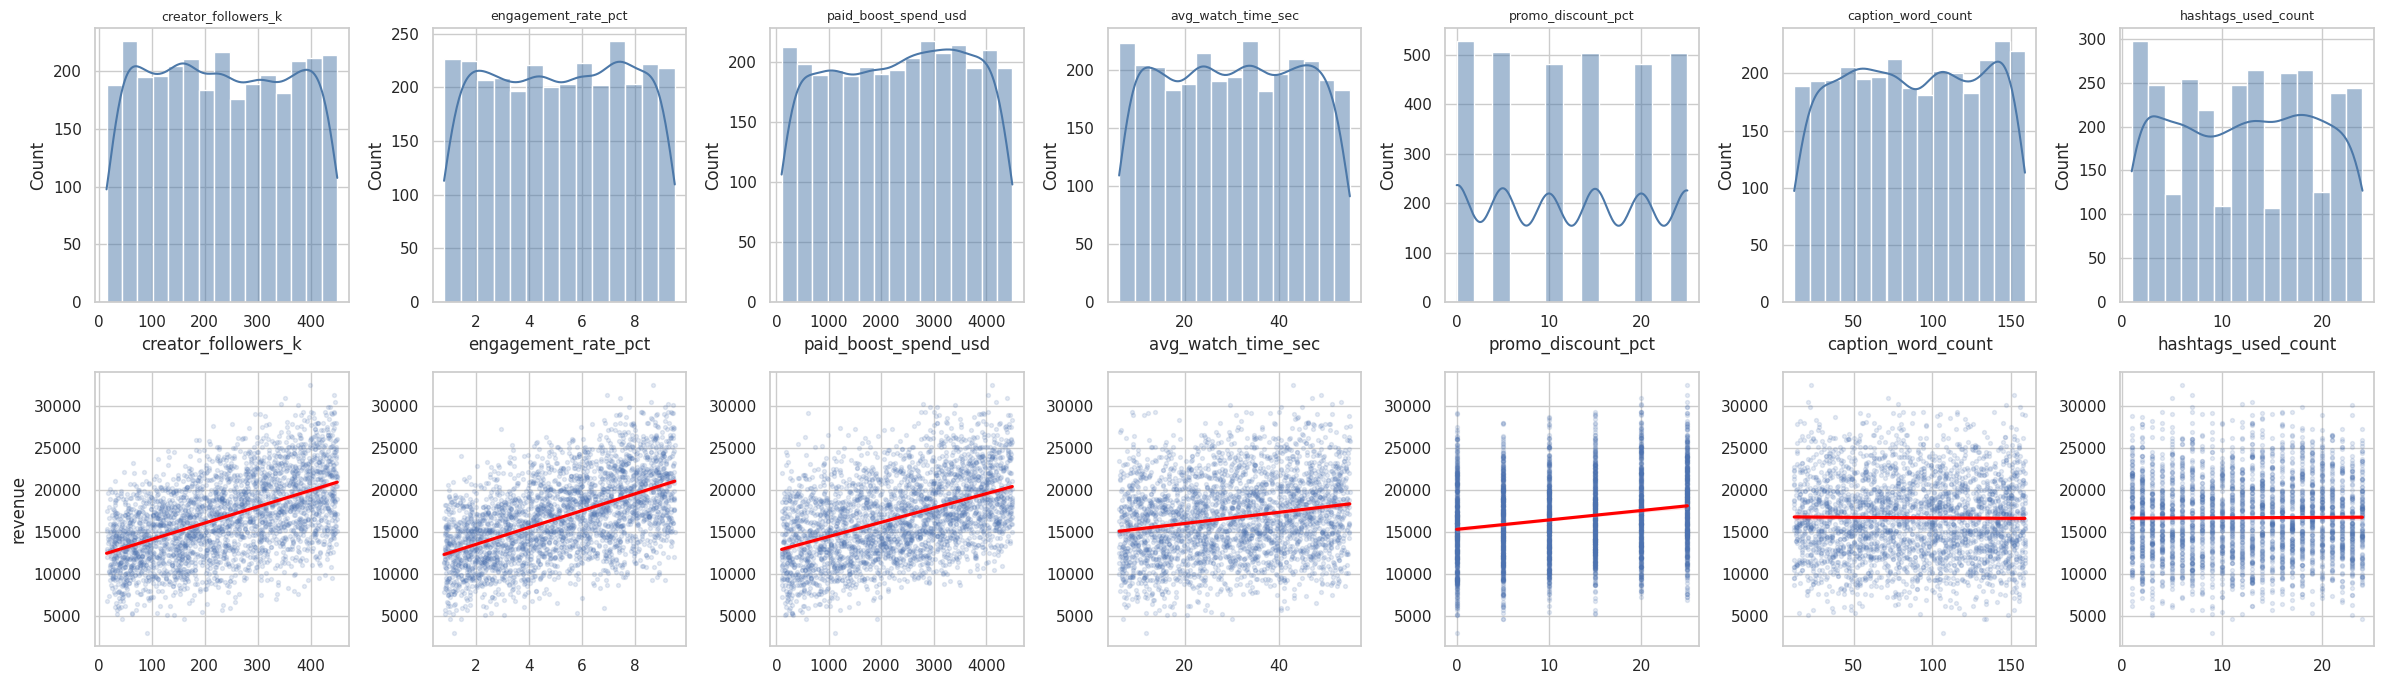

In [32]:
# --- Numeric features: distributions and relationship with target ---
fig, axes = plt.subplots(2, 7, figsize=(24, 7))
for j, c in enumerate(num_r):
    sns.histplot(df_r[c], kde=True, ax=axes[0, j], color="#4c78a8"); axes[0, j].set_title(c, fontsize=9)
    sns.regplot(x=c, y=TARGET_R, data=df_r, ax=axes[1, j], scatter_kws={"alpha": 0.15, "s": 8},
                line_kws={"color": "red"})
    axes[1, j].set_ylabel("revenue" if j == 0 else ""); axes[1, j].set_xlabel("")
plt.tight_layout(); plt.show()

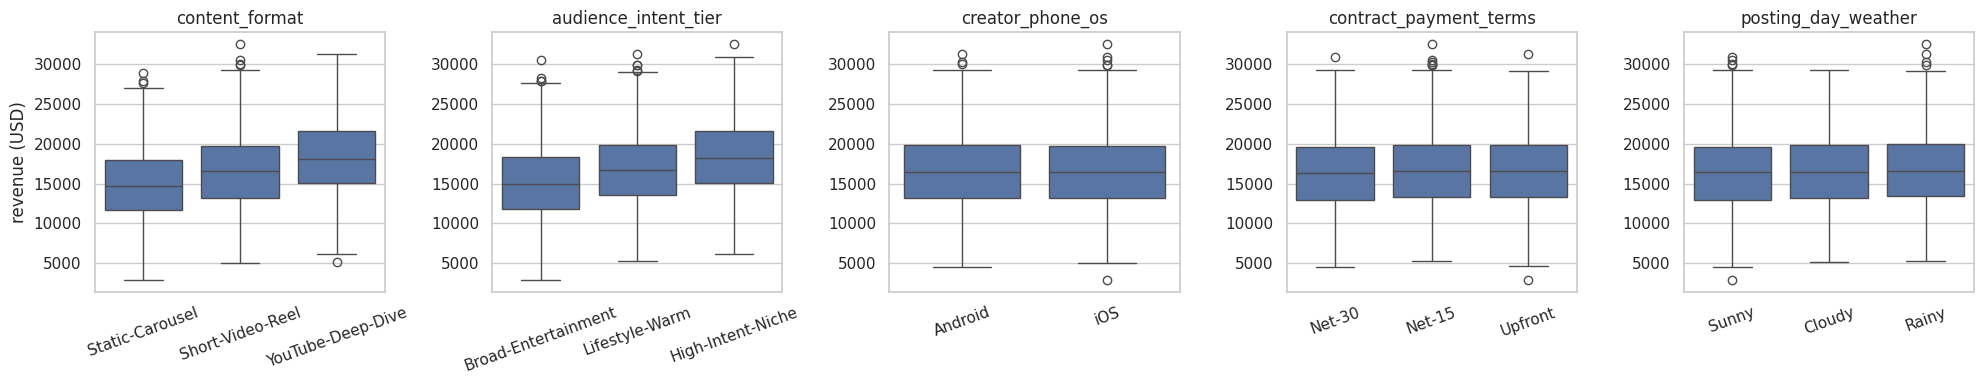

In [33]:
# --- Categorical features vs target ---
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, c in zip(axes, cat_r):
    order = df_r.groupby(c)[TARGET_R].mean().sort_values().index
    sns.boxplot(x=c, y=TARGET_R, data=df_r, order=order, ax=ax)
    ax.set_title(c); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
    ax.set_ylabel("revenue (USD)" if c == cat_r[0] else "")
plt.tight_layout(); plt.show()

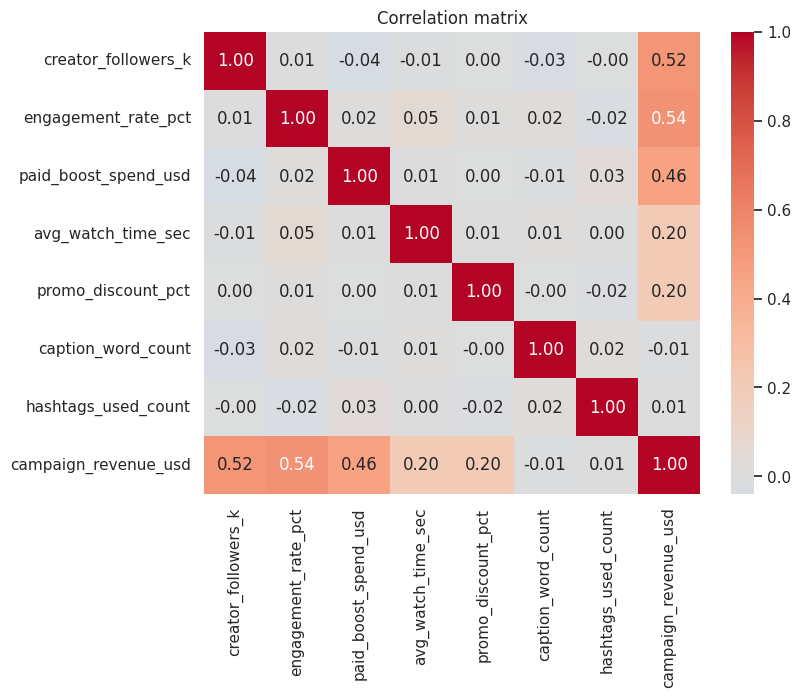

Correlation with target:
engagement_rate_pct     0.5365
creator_followers_k     0.5193
paid_boost_spend_usd    0.4560
promo_discount_pct      0.2033
avg_watch_time_sec      0.1982
hashtags_used_count     0.0069
caption_word_count     -0.0105


In [34]:
# --- Correlation heatmap ---
corr_r = df_r[num_r + [TARGET_R]].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_r, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix"); plt.show()
print("Correlation with target:")
print(corr_r[TARGET_R].drop(TARGET_R).sort_values(ascending=False).to_string())

### Statistical significance of each feature vs the target
* **Numeric:** Pearson correlation test (r and p-value).
* **Categorical:** one-way ANOVA (does mean revenue differ across the levels?).

Features with **p ≥ 0.05** have no statistically detectable relationship with revenue.

In [35]:
rows = []
for c in num_r:
    r_, p = stats.pearsonr(df_r[c], df_r[TARGET_R])
    rows.append({"feature": c, "test": "Pearson r", "statistic": r_, "p_value": p})
for c in cat_r:
    groups = [g[TARGET_R].values for _, g in df_r.groupby(c)]
    f_, p = stats.f_oneway(*groups)
    rows.append({"feature": c, "test": "ANOVA F", "statistic": f_, "p_value": p})

sig_r = pd.DataFrame(rows).set_index("feature")
sig_r["significant (p<0.05)"] = sig_r["p_value"] < 0.05
display(sig_r.sort_values("p_value"))

,test,statistic,p_value,significant (p<0.05)
feature,,,,
engagement_rate_pct,Pearson r,0.5365,0.0000,True
creator_followers_k,Pearson r,0.5193,0.0000,True
paid_boost_spend_usd,Pearson r,0.4560,0.0000,True
audience_intent_tier,ANOVA F,112.0505,0.0000,True
content_format,ANOVA F,96.3768,0.0000,True
promo_discount_pct,Pearson r,0.2033,0.0000,True
avg_watch_time_sec,Pearson r,0.1982,0.0000,True
posting_day_weather,ANOVA F,1.2147,0.2970,False
contract_payment_terms,ANOVA F,0.8841,0.4132,False


**EDA findings (regression)**
* **Strongest drivers:** `engagement_rate_pct`, `creator_followers_k`, `paid_boost_spend_usd` (correlations ≈ 0.45–0.55), followed by `promo_discount_pct` and `avg_watch_time_sec` (≈ 0.20).
* **Categoricals that matter:** `audience_intent_tier` (High-Intent-Niche > Lifestyle-Warm > Broad-Entertainment) and `content_format` (YouTube-Deep-Dive > Short-Video-Reel > Static-Carousel).
* **Likely noise:** `caption_word_count`, `hashtags_used_count`, `creator_phone_os`, `contract_payment_terms`, `posting_day_weather` — flat relationships; the tests above decide formally.
* The target is roughly symmetric (low skew) so no log-transform is needed.

## B3. Data Preprocessing & Feature Selection

In [36]:
df_r_clean = df_r.drop_duplicates().reset_index(drop=True)
print("Rows before/after de-duplication:", len(df_r), "/", len(df_r_clean))
print("Total missing values:", int(df_r_clean.isna().sum().sum()))

selected_r = sig_r.index[sig_r["significant (p<0.05)"]].tolist()
dropped_r = [c for c in sig_r.index if c not in selected_r]
print("\nSelected features:", selected_r)
print("Dropped (no significant relationship with target):", dropped_r)

X_all_r = df_r_clean.drop(columns=[TARGET_R])
y_r = df_r_clean[TARGET_R]
X_train_all_r, X_test_all_r, y_train_r, y_test_r = train_test_split(
    X_all_r, y_r, test_size=0.20, random_state=RS)

X_train_r, X_test_r = X_train_all_r[selected_r], X_test_all_r[selected_r]
sel_num_r = [c for c in num_r if c in selected_r]
sel_cat_r = [c for c in cat_r if c in selected_r]
print(f"\nTrain: {X_train_r.shape}  Test: {X_test_r.shape}")
print("Numeric (scaled):", sel_num_r)
print("Categorical (one-hot):", sel_cat_r)

Rows before/after de-duplication: 3000 / 3000
Total missing values: 0

Selected features: ['creator_followers_k', 'engagement_rate_pct', 'paid_boost_spend_usd', 'avg_watch_time_sec', 'promo_discount_pct', 'content_format', 'audience_intent_tier']
Dropped (no significant relationship with target): ['caption_word_count', 'hashtags_used_count', 'creator_phone_os', 'contract_payment_terms', 'posting_day_weather']

Train: (2400, 7)  Test: (600, 7)
Numeric (scaled): ['creator_followers_k', 'engagement_rate_pct', 'paid_boost_spend_usd', 'avg_watch_time_sec', 'promo_discount_pct']
Categorical (one-hot): ['content_format', 'audience_intent_tier']


**Preprocessing design.** Same philosophy as Part A: no feature outliers to treat, categorical variables one-hot encoded, numerics standardised, and everything wrapped in a `Pipeline` so scaling is fitted on training folds only. The split is a plain random 80/20 split (the target is continuous).

## B4. Model Development & Cross-Validation

**Models chosen and why**

| Model | Why it suits this dataset |
|---|---|
| **Baseline – `DummyRegressor`** | Always predicts the mean revenue; defines "no skill" (R² ≈ 0). |
| **Ridge Regression** | Revenue shows strong, fairly linear relationships with reach, engagement and spend; Ridge is the interpretable, regularised linear model. |
| **Random Forest** | Captures non-linearities and interactions (e.g. followers × engagement) and is robust to the few extreme-revenue campaigns. |
| **Gradient Boosting** | Often the best tabular regressor; sequentially corrects residual errors. |

Evaluation uses **5-fold CV** (shuffled `KFold`) on the training set.

In [37]:
models_r = {
    "Baseline (Dummy Mean)": DummyRegressor(strategy="mean"),
    "Ridge Regression":      Ridge(random_state=RS),
    "Random Forest":         RandomForestRegressor(n_estimators=200, random_state=RS, n_jobs=-1),
    "Gradient Boosting":     GradientBoostingRegressor(random_state=RS),
}
scoring_r = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}
kf = KFold(n_splits=5, shuffle=True, random_state=RS)

cv_rows = []
for name, model in models_r.items():
    pipe = make_pipe(model, sel_num_r, [], sel_cat_r)
    res = cross_validate(pipe, X_train_r, y_train_r, cv=kf, scoring=scoring_r,
                         return_train_score=True, n_jobs=-1)
    cv_rows.append({"Model": name,
                    "MAE": -res["test_mae"].mean(),
                    "RMSE": -res["test_rmse"].mean(),
                    "R2": res["test_r2"].mean(),
                    "RMSE std": res["test_rmse"].std(),
                    "R2 std": res["test_r2"].std(),
                    "Train R2": res["train_r2"].mean()})
cv_r = pd.DataFrame(cv_rows).set_index("Model")
print("5-fold CV results (default hyper-parameters, training data only)")
display(cv_r)

5-fold CV results (default hyper-parameters, training data only)


,MAE,RMSE,R2,RMSE std,R2 std,Train R2
Model,,,,,,
Baseline (Dummy Mean),"3,828.8891","4,728.5672",-0.0002,124.0200,0.0002,0.0000
Ridge Regression,611.9183,776.8957,0.9729,13.9128,0.0016,0.9732
Random Forest,"1,092.7595","1,387.2376",0.9136,66.6443,0.0087,0.9881
Gradient Boosting,634.7866,799.2149,0.9714,41.9578,0.0025,0.9864


In [38]:
# Feature-selection check: all features vs selected features
check_rows = []
for label, (n_, c_) in {"All 12 features": (num_r, cat_r),
                        f"Selected {len(selected_r)} features": (sel_num_r, sel_cat_r)}.items():
    for name in ["Ridge Regression", "Random Forest"]:
        pipe = make_pipe(clone(models_r[name]), n_, [], c_)
        r = cross_validate(pipe, X_train_all_r[n_ + c_], y_train_r, cv=kf,
                           scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"}, n_jobs=-1)
        check_rows.append({"Feature set": label, "Model": name,
                           "CV RMSE": -r["test_rmse"].mean(), "CV R2": r["test_r2"].mean()})
display(pd.DataFrame(check_rows))

,Feature set,Model,CV RMSE,CV R2
0,All 12 features,Ridge Regression,777.0499,0.9729
1,All 12 features,Random Forest,"1,506.4982",0.8981
2,Selected 7 features,Ridge Regression,776.8957,0.9729
3,Selected 7 features,Random Forest,"1,387.2376",0.9136


**Observation.** Dropping the insignificant columns leaves accuracy essentially unchanged (or slightly better), so they carry no useful signal — a smaller input form is also friendlier for users of the deployed app.

## B5. Hyperparameter Tuning (GridSearchCV)

In [39]:
param_grids_r = {
    "Ridge Regression": {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [5, 8, None],
        "model__min_samples_leaf": [1, 5, 10],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3, 4],
    },
}

searches_r = {}
for name, grid in param_grids_r.items():
    t0 = time.time()
    pipe = make_pipe(clone(models_r[name]), sel_num_r, [], sel_cat_r)
    gs = GridSearchCV(pipe, grid, scoring=scoring_r, refit="rmse", cv=kf, n_jobs=-1)
    gs.fit(X_train_r, y_train_r)
    searches_r[name] = gs
    print(f"{name:18s} | best CV RMSE = {-gs.best_score_:,.1f} | "
          f"{len(gs.cv_results_['params'])} combos | {time.time()-t0:.0f}s")
    print("   best params:", gs.best_params_)

rows = []
for name, gs in searches_r.items():
    i = gs.best_index_
    rows.append({"Model": name,
                 "CV RMSE (tuned)": -gs.cv_results_["mean_test_rmse"][i],
                 "CV R2 (tuned)": gs.cv_results_["mean_test_r2"][i],
                 "CV RMSE (default)": cv_r.loc[name, "RMSE"]})
tuned_r = pd.DataFrame(rows).set_index("Model")
tuned_r["RMSE improvement"] = tuned_r["CV RMSE (default)"] - tuned_r["CV RMSE (tuned)"]
display(tuned_r)

Ridge Regression   | best CV RMSE = 776.9 | 6 combos | 0s
   best params: {'model__alpha': 0.01}
Random Forest      | best CV RMSE = 1,383.7 | 18 combos | 182s
   best params: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}
Gradient Boosting  | best CV RMSE = 672.4 | 12 combos | 35s
   best params: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}


,CV RMSE (tuned),CV R2 (tuned),CV RMSE (default),RMSE improvement
Model,,,,
Ridge Regression,776.8851,0.9729,776.8957,0.0106
Random Forest,"1,383.7446",0.9140,"1,387.2376",3.4930
Gradient Boosting,672.3912,0.9797,799.2149,126.8237


## B6. Model Evaluation (held-out test set)

**Which metric matters most for this business problem?**

| Metric | Meaning | Business relevance |
|---|---|---|
| **MAE** | Average absolute miss in USD | Easiest to communicate: "on average we are off by $X per campaign" |
| **RMSE** | Like MAE but punishes large misses | Important because a big over-estimate can mean a badly-spent budget → our tuning/selection criterion |
| **R²** | Share of revenue variance explained | Overall explanatory power; compares models independent of currency |

In [40]:
def reg_metrics(y_true, pred):
    return {"MAE": mean_absolute_error(y_true, pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, pred))),
            "R2": r2_score(y_true, pred)}

base_pipe_r = make_pipe(clone(models_r["Baseline (Dummy Mean)"]), sel_num_r, [], sel_cat_r).fit(X_train_r, y_train_r)
fitted_r = {"Baseline (Dummy Mean)": base_pipe_r}
fitted_r.update({n: gs.best_estimator_ for n, gs in searches_r.items()})

rows, preds_r = [], {}
for name, est in fitted_r.items():
    preds_r[name] = est.predict(X_test_r)
    rows.append({"Model": name, **reg_metrics(y_test_r, preds_r[name])})
test_r = pd.DataFrame(rows).set_index("Model")
print("Test-set performance")
display(test_r)

Test-set performance


,MAE,RMSE,R2
Model,,,
Baseline (Dummy Mean),"3,878.9846","4,811.2663",-0.0004
Ridge Regression,624.5011,797.5067,0.9725
Random Forest,"1,014.9986","1,266.8112",0.9306
Gradient Boosting,529.9752,665.3593,0.9809


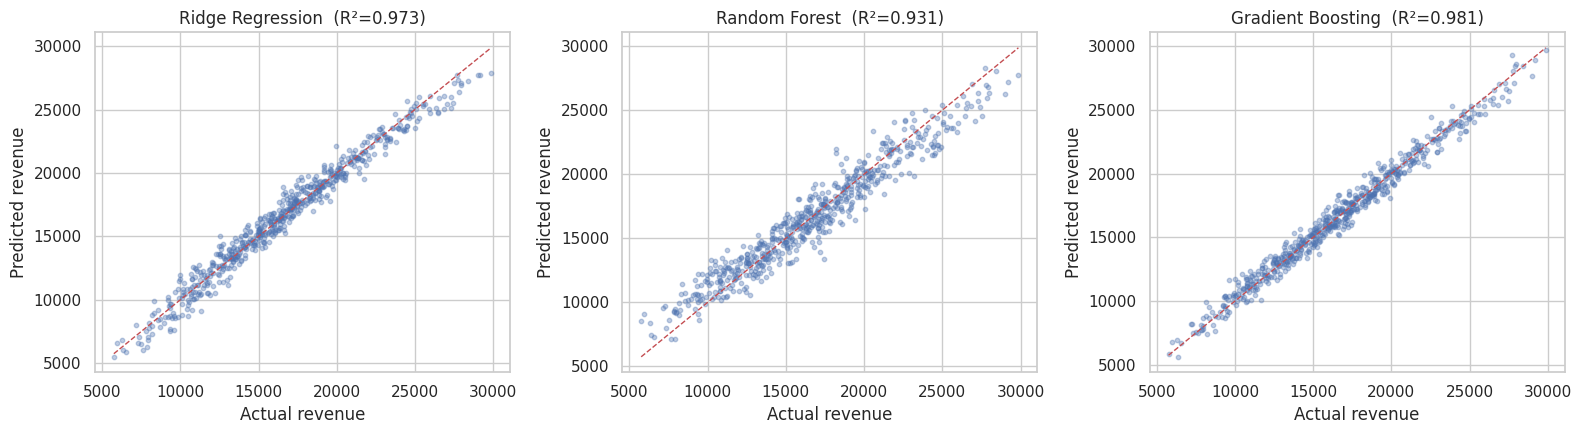

In [41]:
names3_r = list(searches_r.keys())
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
lim = [y_test_r.min(), y_test_r.max()]
for ax, name in zip(axes, names3_r):
    ax.scatter(y_test_r, preds_r[name], alpha=0.35, s=10)
    ax.plot(lim, lim, "r--", lw=1)
    ax.set_xlabel("Actual revenue"); ax.set_ylabel("Predicted revenue")
    ax.set_title(f"{name}  (R²={test_r.loc[name, 'R2']:.3f})")
plt.tight_layout(); plt.show()

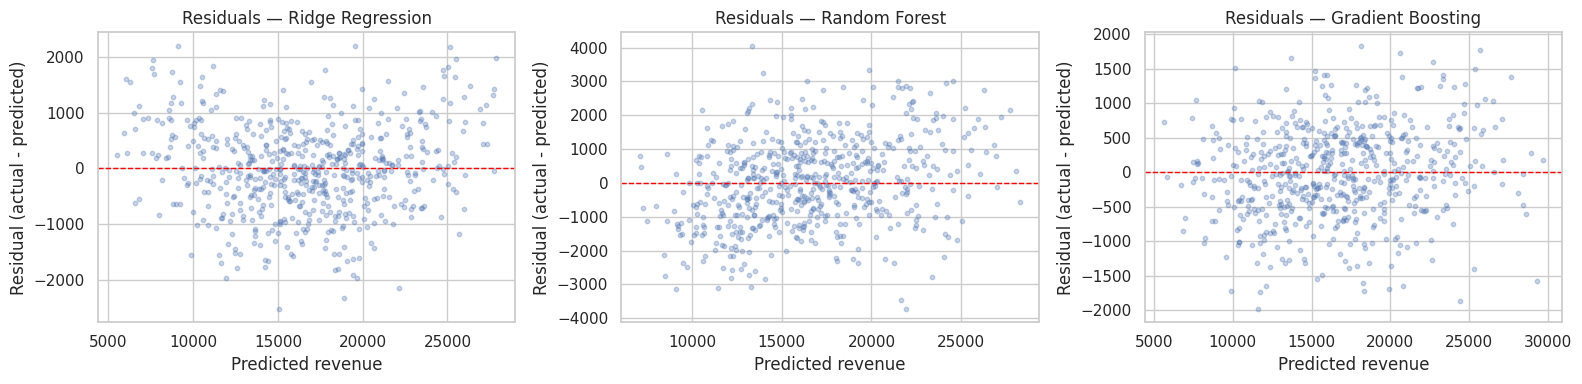

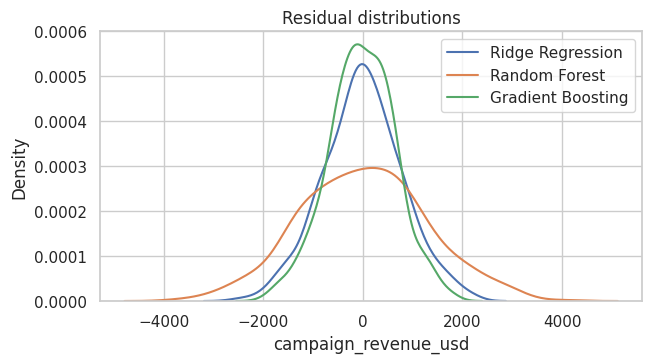

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, name in zip(axes, names3_r):
    resid = y_test_r - preds_r[name]
    ax.scatter(preds_r[name], resid, alpha=0.3, s=10)
    ax.axhline(0, color="red", ls="--", lw=1)
    ax.set_xlabel("Predicted revenue"); ax.set_ylabel("Residual (actual - predicted)")
    ax.set_title(f"Residuals — {name}")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
for name in names3_r:
    sns.kdeplot(y_test_r - preds_r[name], ax=ax, label=name)
ax.set_title("Residual distributions"); ax.legend(); plt.show()

## B7. Model Comparison & Final Model Selection

**Selection criteria:** (1) cross-validated RMSE (decision basis, not the test set), (2) train-vs-test gap, (3) stability across folds, (4) training time, (5) interpretability — if two models are practically tied (within 1 % RMSE), the simpler one wins.

In [43]:
complexity_r = {"Ridge Regression": 1, "Random Forest": 2, "Gradient Boosting": 3}
rows = []
for name, gs in searches_r.items():
    i = gs.best_index_
    train_r2 = r2_score(y_train_r, gs.best_estimator_.predict(X_train_r))
    rows.append({
        "Model": name,
        "CV RMSE": -gs.cv_results_["mean_test_rmse"][i],
        "CV RMSE std": gs.cv_results_["std_test_rmse"][i],
        "CV R2": gs.cv_results_["mean_test_r2"][i],
        "Test MAE": test_r.loc[name, "MAE"],
        "Test RMSE": test_r.loc[name, "RMSE"],
        "Test R2": test_r.loc[name, "R2"],
        "Overfit gap (Train-Test R2)": train_r2 - test_r.loc[name, "R2"],
        "Refit time (s)": gs.refit_time_,
        "Complexity (1=simple)": complexity_r[name],
    })
compare_r = pd.DataFrame(rows).set_index("Model")
display(compare_r)

best_rmse = compare_r["CV RMSE"].min()
candidates = compare_r[compare_r["CV RMSE"] <= best_rmse * 1.01]
final_name_r = candidates["Complexity (1=simple)"].idxmin()
final_pipe_r = searches_r[final_name_r].best_estimator_
print(f"\n>>> FINAL REGRESSION MODEL: {final_name_r}")
print("    Candidates within 1% of best CV RMSE:", list(candidates.index))
print("    Best params:", searches_r[final_name_r].best_params_)
print("    Test metrics:", {k: round(v, 4) for k, v in test_r.loc[final_name_r].items()})

,CV RMSE,CV RMSE std,CV R2,Test MAE,Test RMSE,Test R2,Overfit gap (Train-Test R2),Refit time (s),Complexity (1=simple)
Model,,,,,,,,,
Ridge Regression,776.8851,13.9518,0.9729,624.5011,797.5067,0.9725,0.0007,0.0099,1
Random Forest,"1,383.7446",68.5609,0.9140,"1,014.9986","1,266.8112",0.9306,0.0587,5.3985,2
Gradient Boosting,672.3912,26.3872,0.9797,529.9752,665.3593,0.9809,0.0106,1.1295,3



>>> FINAL REGRESSION MODEL: Gradient Boosting
    Candidates within 1% of best CV RMSE: ['Gradient Boosting']
    Best params: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
    Test metrics: {'MAE': 529.9752, 'RMSE': 665.3593, 'R2': 0.9809}


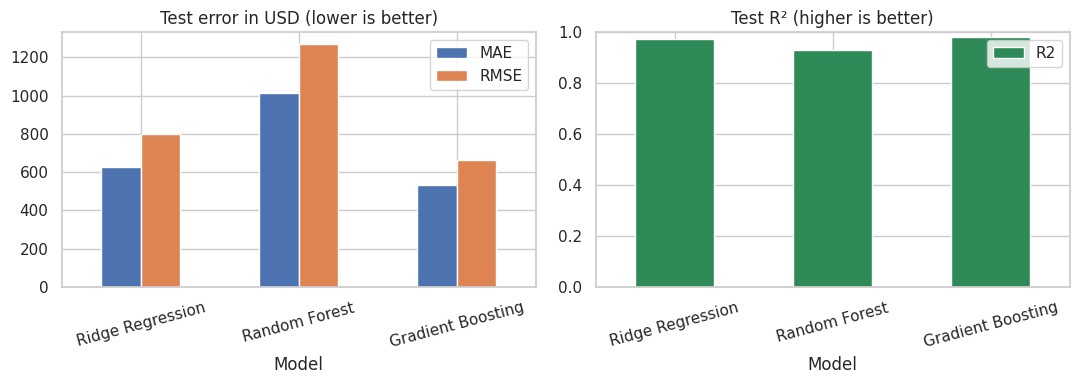

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
test_r.drop(index="Baseline (Dummy Mean)")[["MAE", "RMSE"]].plot(kind="bar", ax=axes[0], rot=15)
axes[0].set_title("Test error in USD (lower is better)")
test_r.drop(index="Baseline (Dummy Mean)")[["R2"]].plot(kind="bar", ax=axes[1], rot=15, color="seagreen")
axes[1].set_ylim(0, 1); axes[1].set_title("Test R² (higher is better)")
plt.tight_layout(); plt.show()

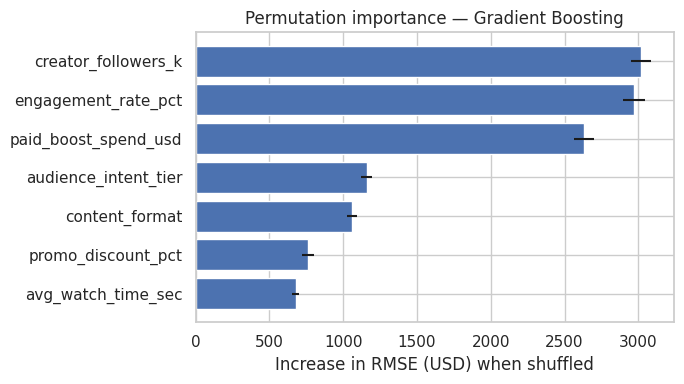

In [46]:
pi = permutation_importance(final_pipe_r, X_test_r, y_test_r, scoring="neg_root_mean_squared_error",
                            n_repeats=15, random_state=RS, n_jobs=-1)
imp_r = pd.Series(pi.importances_mean, index=X_test_r.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp_r.index, imp_r.values, xerr=pi.importances_std[np.argsort(pi.importances_mean)])
ax.set_xlabel("Increase in RMSE (USD) when shuffled")
ax.set_title(f"Permutation importance — {final_name_r}")
plt.tight_layout(); plt.show()

**Justification of the final model.** The code selects objectively (lowest CV RMSE, simpler model preferred when tied within 1 %). In the report, cite its CV/test RMSE, MAE and R², the small train-test gap, and the stability across folds.

## B8. Business Interpretation & Limitations (Regression)

**What the prediction means.** The model outputs the **expected trackable revenue (USD) within 14 days** of a post, given the creator's reach, engagement, boost spend, content format, audience intent and promo discount. The test **MAE** is the typical size of the error, so a prediction should be read as *"about $X ± MAE"*, not an exact figure.

**How it supports decisions**
* **Creator selection:** compare candidates on predicted revenue per dollar of fee.
* **Budget allocation:** see how much extra revenue a higher paid-boost budget or promo discount is expected to deliver (what-if analysis through the app).
* **Content strategy:** which format (e.g. YouTube deep-dive vs static carousel) and audience tier (high-intent niche vs broad entertainment) to prioritise.
* **Forecasting & targets:** set realistic revenue targets and detect under-performing campaigns early.

**Limitations**
* Data appears **synthetic**; real campaign outcomes involve brand fit, seasonality, creative quality and competitor activity that are absent here.
* Associations are **correlational** — raising spend/discount in the app shows *predicted association*, not a guaranteed causal lift. Diminishing returns beyond the observed ranges are unknown.
* The model should **not extrapolate** outside the training ranges (e.g. > 450 k followers, > $4,500 boost, > 25 % discount).
* Revenue is attributed only through trackable promo codes within 14 days — longer-term brand effects are excluded.
* Few extreme "viral" campaigns exist, so very high revenues are predicted less reliably.

---
# PART D — Wrap-up
---

In [ ]:
summary = pd.DataFrame({
    "Project": ["A – Classification (returns)", "B – Regression (campaign revenue)"],
    "Final model": [final_name_c, final_name_r],
    "Key metrics (test)": [
        f"F1={test_c.loc[final_name_c,'F1']:.3f}, ROC-AUC={test_c.loc[final_name_c,'ROC-AUC']:.3f}, "
        f"Recall={test_c.loc[final_name_c,'Recall']:.3f}, Precision={test_c.loc[final_name_c,'Precision']:.3f}",
        f"MAE=${test_r.loc[final_name_r,'MAE']:,.0f}, RMSE=${test_r.loc[final_name_r,'RMSE']:,.0f}, "
        f"R²={test_r.loc[final_name_r,'R2']:.3f}"],
    "Features kept": [", ".join(selected_c), ", ".join(selected_r)],
    "Features dropped (noise)": [", ".join(dropped_c), ", ".join(dropped_r)],
}).set_index("Project")
pd.set_option("display.max_colwidth", None)
display(summary.T)

### Key take-aways
1. **Signal vs. noise:** in both datasets a handful of meaningful drivers explain the target, while several "cosmetic" columns (browser, packaging colour, phone OS, weather, …) add nothing. Statistical tests + a with/without-feature CV check justify dropping them.
2. **Pipelines prevent leakage and simplify deployment:** preprocessing and model travel together as one object.
3. **Selection by cross-validation, confirmation on the test set:** the test set was touched only after tuning and model choice.
4. **Practical value:** the classifier gives a return-risk score for each order at checkout; the regressor gives a revenue estimate with a typical error band for planning influencer campaigns.

### Limitations (overall)
Synthetic-looking data · correlation ≠ causation · no time component · asymmetric business costs not modelled · models need monitoring and periodic retraining on real data.